# 01 · Exploratory data analysis: RAVDESS speech

**Case study:** speaker-independent speech emotion recognition (Group 19).

Before building any model we check the data: is it complete, are the labels what the authors describe, how balanced are the classes, and what do different emotions look and sound like?

**Dataset:** RAVDESS audio-only speech (Livingstone & Russo, 2018, *PLoS ONE* 13(5): e0196391), CC BY-NC-SA 4.0. 24 professional actors (12 male, 12 female) each say two fixed sentences in eight emotions.

**File name code**, e.g. `03-01-06-01-02-01-12.wav`:

| Position | Meaning | Values |
|---|---|---|
| 1 | Modality | 03 = audio-only |
| 2 | Vocal channel | 01 = speech |
| 3 | Emotion | 01 neutral, 02 calm, 03 happy, 04 sad, 05 angry, 06 fearful, 07 disgust, 08 surprised |
| 4 | Intensity | 01 normal, 02 strong (neutral has no strong version) |
| 5 | Statement | 01 "Kids are talking by the door", 02 "Dogs are sitting by the door" |
| 6 | Repetition | 01 or 02 |
| 7 | Actor | 01–24 (odd = male, even = female) |

In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from ser.config import EMOTION_ORDER, SAMPLE_RATE, TRIM_TOP_DB
from ser.dataset import load_metadata
from ser.features import load_clip
from ser.plots import GREY, INK_2, SEQ_CMAP, save, set_style

set_style()

## 1. Load metadata and verify the dataset

In [2]:
meta = load_metadata()
print(f"Clips: {len(meta)}  |  Actors: {meta.actor.nunique()}  |  "
      f"Male clips: {(meta.gender == 'male').sum()}  |  Female clips: {(meta.gender == 'female').sum()}")
meta.head()

Clips: 1440  |  Actors: 24  |  Male clips: 720  |  Female clips: 720


,file,path,actor,gender,emotion_id,emotion,intensity,statement,repetition
0,03-01-01-01-01-01-01.wav,C:\Users\godwi\speech-emotion-recognition\data...,1,male,1,neutral,normal,Kids are talking by the door,1
1,03-01-01-01-01-02-01.wav,C:\Users\godwi\speech-emotion-recognition\data...,1,male,1,neutral,normal,Kids are talking by the door,2
2,03-01-01-01-02-01-01.wav,C:\Users\godwi\speech-emotion-recognition\data...,1,male,1,neutral,normal,Dogs are sitting by the door,1
3,03-01-01-01-02-02-01.wav,C:\Users\godwi\speech-emotion-recognition\data...,1,male,1,neutral,normal,Dogs are sitting by the door,2
4,03-01-02-01-01-01-01.wav,C:\Users\godwi\speech-emotion-recognition\data...,1,male,2,calm,normal,Kids are talking by the door,1


In [3]:
# Checks against the published description of the dataset
assert len(meta) == 1440
assert meta.actor.nunique() == 24
assert (meta.groupby("actor").size() == 60).all()
counts = meta.emotion.value_counts()
assert counts["neutral"] == 96 and (counts.drop("neutral") == 192).all()
assert not meta.query("emotion == 'neutral'").intensity.eq("strong").any()
print("All dataset checks passed.")

All dataset checks passed.


## 2. Audio format and clip length

In [4]:
info = pd.DataFrame([{"sr": i.samplerate, "channels": i.channels, "duration": i.duration}
                     for i in (sf.info(p) for p in meta.path)])
print("Sample rates:", info.sr.value_counts().to_dict())
print("Channels:", info.channels.value_counts().to_dict(), "(stereo files are averaged to mono)")
info.duration.describe().round(2).to_frame("raw duration (s)").T

Sample rates: {48000: 1440}
Channels: {1: 1435, 2: 5} (stereo files are averaged to mono)


,count,mean,std,min,25%,50%,75%,max
raw duration (s),1440.0,3.7,0.34,2.94,3.47,3.67,3.87,5.27


Every recording starts and ends with silence. We trim it (anything more than 30 dB below the clip's peak) so the statistics describe speech, not silence. The plot compares lengths before and after trimming.

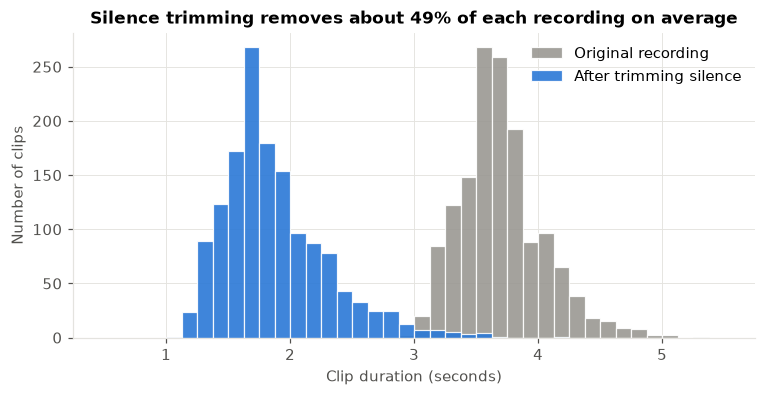

,count,mean,std,min,25%,50%,75%,max
duration_raw,1440.0,3.70,0.34,2.94,3.47,3.67,3.87,5.27
duration_trim,1440.0,1.87,0.42,1.09,1.58,1.79,2.09,4.25


In [5]:
trimmed = np.array([len(load_clip(p)) / SAMPLE_RATE for p in meta.path])
meta["duration_raw"] = info.duration.values
meta["duration_trim"] = trimmed

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0.5, 5.5, 41)
ax.hist(meta.duration_raw, bins=bins, color=GREY, alpha=0.9, label="Original recording", edgecolor="white", linewidth=0.8)
ax.hist(meta.duration_trim, bins=bins, color="#2a78d6", alpha=0.9, label="After trimming silence", edgecolor="white", linewidth=0.8)
ax.set_xlabel("Clip duration (seconds)")
ax.set_ylabel("Number of clips")
ax.set_title("Silence trimming removes about "
             f"{(1 - meta.duration_trim.mean() / meta.duration_raw.mean()) * 100:.0f}% of each recording on average")
ax.legend()
save(fig, "04_duration_trimming")
plt.show()
meta[["duration_raw", "duration_trim"]].describe().round(2).T

## 3. Class balance
Seven emotions have 192 clips each. Neutral has only 96 because it was not recorded at "strong" intensity. Because of this imbalance we report **macro-F1** and **UAR** (unweighted average recall) alongside plain accuracy, since both give every emotion equal weight.

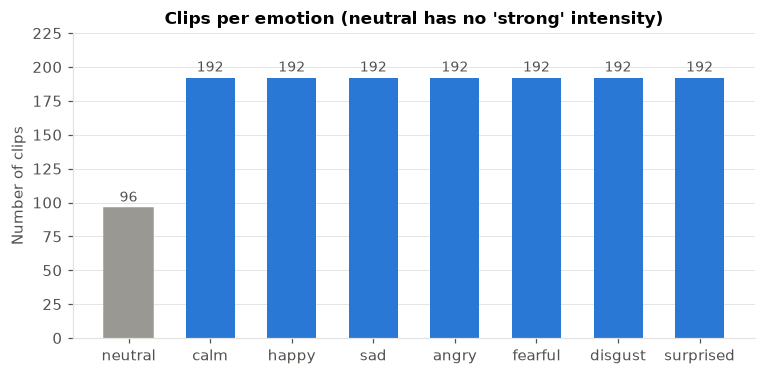

In [6]:
counts = meta.emotion.value_counts().reindex(EMOTION_ORDER)
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(counts.index, counts.values, color="#2a78d6", width=0.6)
bars[0].set_color(GREY)
ax.bar_label(bars, padding=2, color=INK_2, fontsize=9)
ax.set_ylabel("Number of clips")
ax.set_title("Clips per emotion (neutral has no 'strong' intensity)")
ax.set_ylim(0, 225)
ax.grid(axis="x", visible=False)
save(fig, "01_class_distribution")
plt.show()

In [7]:
pd.crosstab(meta.emotion, meta.intensity).reindex(EMOTION_ORDER)

intensity,normal,strong
emotion,,
neutral,96,0
calm,96,96
happy,96,96
sad,96,96
angry,96,96
fearful,96,96
disgust,96,96
surprised,96,96


## 4. What does each emotion look like?
Same actor (Actor 02, female), same sentence, same repetition: only the emotion changes. Strong intensity is used where it exists.

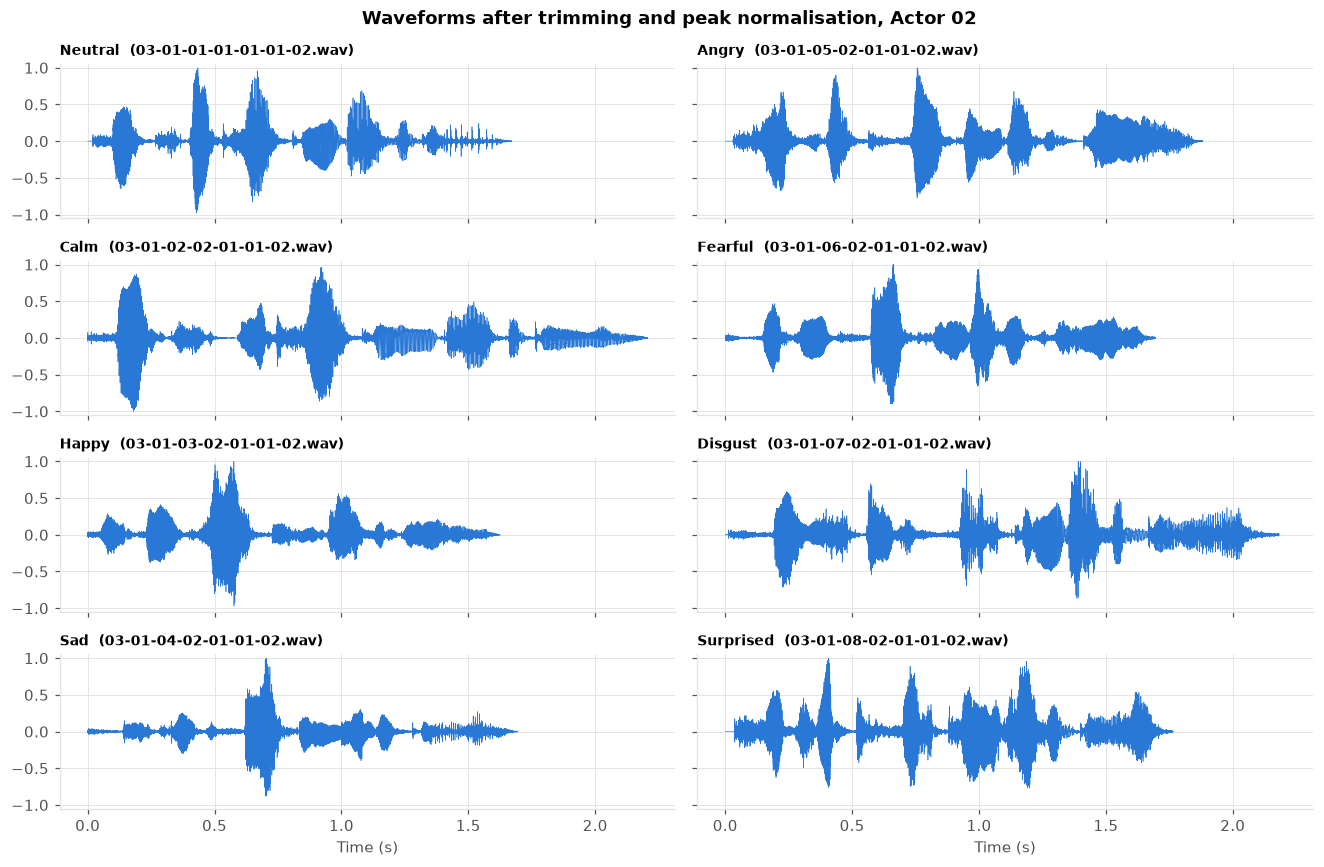

In [8]:
def example_clip(emotion, actor=2, statement="Kids are talking by the door"):
    rows = meta.query("actor == @actor and emotion == @emotion and statement == @statement and repetition == 1")
    pick = rows[rows.intensity == "strong"] if (rows.intensity == "strong").any() else rows
    return pick.iloc[0]

examples = {e: example_clip(e) for e in EMOTION_ORDER}

fig, axes = plt.subplots(4, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, (emo, row) in zip(axes.T.flat, examples.items()):
    y = load_clip(row.path)
    t = np.arange(len(y)) / SAMPLE_RATE
    ax.plot(t, y, color="#2a78d6", linewidth=0.4)
    ax.set_title(f"{emo.capitalize()}  ({row.file})", fontsize=9, loc="left")
    ax.set_ylim(-1.05, 1.05)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.suptitle("Waveforms after trimming and peak normalisation, Actor 02", fontweight="bold")
fig.tight_layout()
save(fig, "02_waveforms_by_emotion")
plt.show()

Mel-spectrograms show energy over time (x) and frequency (y). Look for: **angry** and **surprised** with strong high-frequency energy; **sad** and **calm** with weaker, lower energy; and differences in speaking rate and pitch contour (the curved harmonic lines).

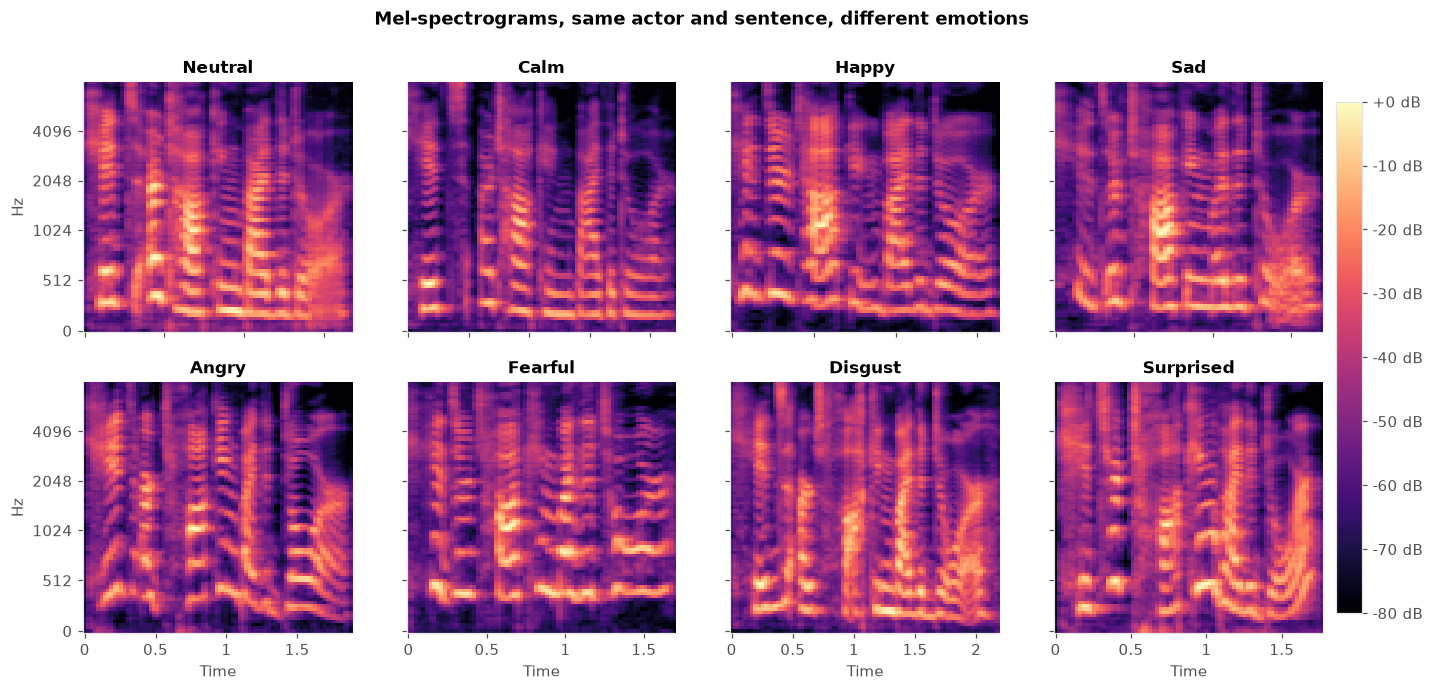

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
for ax, (emo, row) in zip(axes.flat, examples.items()):
    y = load_clip(row.path)
    mel = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_mels=96, fmax=8000)
    img = librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), sr=SAMPLE_RATE, fmax=8000,
                                   x_axis="time", y_axis="mel", ax=ax, cmap="magma", vmin=-80, vmax=0)
    ax.set_title(emo.capitalize())
    ax.label_outer()
fig.colorbar(img, ax=axes, format="%+.0f dB", fraction=0.02, pad=0.01)
fig.suptitle("Mel-spectrograms, same actor and sentence, different emotions", fontweight="bold")
save(fig, "03_mel_spectrograms")
plt.show()

## 5. Speakers matter
Pitch differs far more *between people* than between emotions of the same person. Below, mean pitch per actor shows two clear groups (male and female). A model trained and tested on the same actors could partly learn the voice instead of the emotion. **This is why every experiment holds out whole actors** (speaker-independent evaluation).

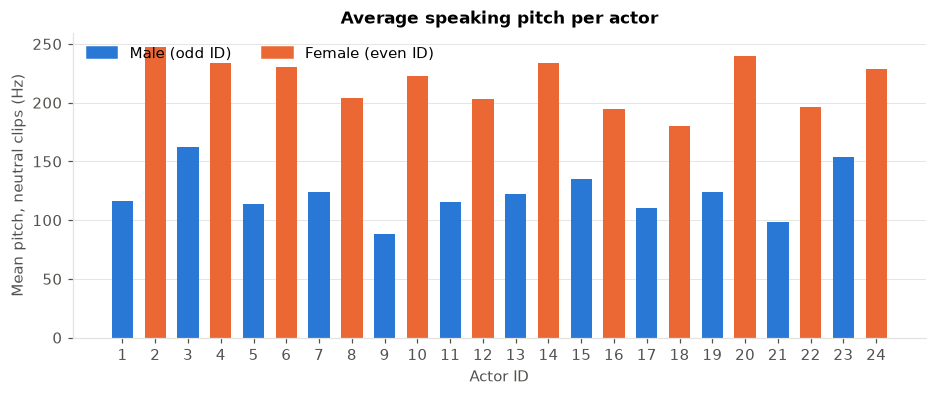

In [10]:
f0 = []
for p in meta.query("emotion == 'neutral'").path:
    y = load_clip(p)
    f, v, _ = librosa.pyin(y, fmin=65, fmax=600, sr=SAMPLE_RATE)
    f0.append(np.nanmean(f[v]) if v.any() else np.nan)
neutral = meta.query("emotion == 'neutral'").assign(f0=f0)
per_actor = neutral.groupby(["actor", "gender"]).f0.mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = ["#2a78d6" if g == "male" else "#eb6834" for g in per_actor.gender]
ax.bar(per_actor.actor.astype(str), per_actor.f0, color=colors, width=0.65)
ax.set_xlabel("Actor ID")
ax.set_ylabel("Mean pitch, neutral clips (Hz)")
ax.set_title("Average speaking pitch per actor")
ax.grid(axis="x", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2a78d6", label="Male (odd ID)"), Patch(color="#eb6834", label="Female (even ID)")],
          loc="upper left", ncols=2)
save(fig, "04b_pitch_per_actor")
plt.show()

## Summary
- The dataset is complete: 1,440 clips, 24 actors × 60 clips, labels match the published description.
- Audio is 48 kHz; we resample to 22.05 kHz mono (speech emotion cues lie well below 11 kHz).
- Neutral is under-represented (96 vs 192), so we report macro-F1 and UAR as well as accuracy.
- Speaker identity has a strong effect on acoustics, so we evaluate on unseen actors only.